In [ ]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("all_tickets_processed_improved_v3.csv")

In [3]:
df.head()

,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [4]:
df.shape

(47837, 2)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47837 entries, 0 to 47836
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Document     47837 non-null  object
 1   Topic_group  47837 non-null  object
dtypes: object(2)
memory usage: 747.6+ KB


In [6]:
#missing values
df.isnull().sum()

Document       0
Topic_group    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.columns

Index(['Document', 'Topic_group'], dtype='object')

In [9]:
df["Topic_group"].value_counts()

Topic_group
Hardware                 13617
HR Support               10915
Access                    7125
Miscellaneous             7060
Storage                   2777
Purchase                  2464
Internal Project          2119
Administrative rights     1760
Name: count, dtype: int64

In [10]:
df["Document"].head()

0    connection with icon icon dear please setup ic...
1    work experience user work experience user hi w...
2    requesting for meeting requesting meeting hi p...
3    reset passwords for external accounts re expir...
4    mail verification warning hi has got attached ...
Name: Document, dtype: object

In [11]:
df["Topic_group"].unique()

array(['Hardware', 'Access', 'Miscellaneous', 'HR Support', 'Purchase',
       'Administrative rights', 'Storage', 'Internal Project'],
      dtype=object)

#### Text cleaning

In [12]:
#to clean unneccesary spaces,special characters(stopwords) in ticket discription before traing

In [13]:
import re #regular expression

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text

df["Cleaned document"] = df["Document"].apply(clean_text)

In [14]:
print(df[["Document", "Cleaned document"]].head())

                                            Document  \
0  connection with icon icon dear please setup ic...   
1  work experience user work experience user hi w...   
2  requesting for meeting requesting meeting hi p...   
3  reset passwords for external accounts re expir...   
4  mail verification warning hi has got attached ...   

                                    Cleaned document  
0  connection with icon icon dear please setup ic...  
1  work experience user work experience user hi w...  
2  requesting for meeting requesting meeting hi p...  
3  reset passwords for external accounts re expir...  
4  mail verification warning hi has got attached ...  


In [15]:
df["Cleaned document"].isnull().sum()

np.int64(0)

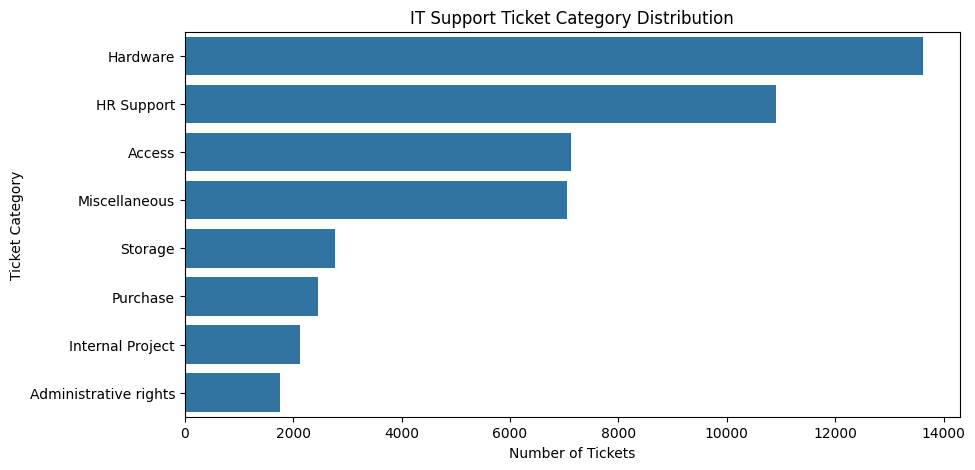

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(data=df, y="Topic_group",
              order=df["Topic_group"].value_counts().index)

plt.title("IT Support Ticket Category Distribution")
plt.xlabel("Number of Tickets")
plt.ylabel("Ticket Category")
plt.show()